# Hysteresis sensitivity analysis: VthCa vs inhibition

This notebook performs a systematic parameter sweep to investigate how hysteresis (persistent inward current effects) depends on:
1. **VthCa**: Calcium channel activation threshold
2. **Inhibition level**: Synaptic inhibition strength

---

## 1. Environment setup

### 1.1 Package imports

In [7]:
# Core packages
using Distributions, Random
using Parameters, Match, SymDict

# Data handling
using JLD2, MAT, CSV, DataFrames, Serialization

# Numerical methods
using DSP, NumericalIntegration
using Optim, JuMP, Ipopt, ForwardDiff, LinearAlgebra

# Visualization
using Plots, CairoMakie, Makie
using Colors, ColorSchemes

println("✓ All packages loaded successfully")

✓ All packages loaded successfully


### 1.2 Load custom functions

In [8]:
# Define path to custom functions (ADJUST THIS PATH FOR YOUR SYSTEM)
folder_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/utils/functions_run_simulations"

# Load all .jl files from the directory
if isdir(folder_path)
    for file in readdir(folder_path)
        if endswith(file, ".jl")
            include(joinpath(folder_path, file))
            println("✓ Loaded: ", file)
        end
    end
else
    error("Functions directory not found. Please update folder_path variable.")
end

✓ Loaded: calculate_rates_with_timebase.jl
✓ Loaded: conv_spikes_rates.jl
✓ Loaded: creation_model.jl
✓ Loaded: creation_model_controller.jl
✓ Loaded: filter_input.jl
✓ Loaded: plot_MN_trajectory.jl
✓ Loaded: plot_spike_raster.jl
✓ Loaded: run_sim.jl
✓ Loaded: run_sim_noise.jl
✓ Loaded: run_sim_onemn.jl
✓ Loaded: sim_ode_online_control_exp.jl


In [9]:
# Define path to custom functions (ADJUST THIS PATH FOR YOUR SYSTEM)
folder_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/utils/functions_optimization/"

# Load all .jl files from the directory
if isdir(folder_path)
    for file in readdir(folder_path)
        if endswith(file, ".jl")
            include(joinpath(folder_path, file))
            println("✓ Loaded: ", file)
        end
    end
else
    error("Functions directory not found. Please update folder_path variable.")
end

✓ Loaded: creation_model_nofacilitation.jl
✓ Loaded: optimization_black_box.jl
✓ Loaded: run_sim_for_one_mn.jl


---

## 2. Model parameters

### 2.1 Basic configuration

In [10]:
# Number of motoneurons to simulate
nr_s = 10

println("Configuration:")
println("  Number of motoneurons: ", nr_s)

Configuration:
  Number of motoneurons: 10


### 2.2 Morphological parameters

In [11]:
# Rheobase with biological variability
rheobase_S = LinRange(3.5, 6.5, nr_s) .+ rand(Normal(0.0, 0.05), nr_s)

# Soma dimensions (converted to cm)
rs_S = LinRange(38.75, 41.25, nr_s) ./ 10000
ls_S = LinRange(77.5, 82.5, nr_s) ./ 10000
rms_S = LinRange(1.15, 1.05, nr_s) .* 1000

# Dendrite dimensions (converted to cm)
rd_S = LinRange(20.75, 31.25, nr_s) ./ 10000
ld_S = LinRange(5500.0, 6800.0, nr_s) ./ 10000
rmd_S = LinRange(14.4, 10.70, nr_s) .* 1000

println("✓ Morphological parameters defined")

✓ Morphological parameters defined


### 2.3 Ion channel conductances

In [12]:
# Maximum conductances (mS/cm²)
max_gna = 30.0
max_gkf_S = ones(nr_s) .* 4.0
max_gks_S = LinRange(16, 25, nr_s)
max_gca_S = LinRange(0.038, 0.029, nr_s)

println("✓ Ion channel conductances defined")

✓ Ion channel conductances defined


### 2.4 Gating kinetics

In [13]:
# Rate constants (ms⁻¹)
αm = ones(nr_s) .* 22.0
βm = ones(nr_s) .* 13.0
αh_S = ones(nr_s) .* 0.5
βh_S = ones(nr_s) .* 4.0
αn_S = ones(nr_s) .* 1.5
βn_S = ones(nr_s) .* 0.1
αq_S = ones(nr_s) .* 1.5
βq_S = LinRange(0.025, 0.038, nr_s)
αp_D = 0.008
βp_D = LinRange(0.014, 0.016, nr_s)

println("✓ Gating kinetics defined")

✓ Gating kinetics defined


### 2.5 Force parameters

In [14]:
# Twitch properties
Apeak_S = LinRange(0.103, 0.123, nr_s)
tpeak_S = LinRange(110.0, 100.0, nr_s)
tetanic_S = LinRange(0.393, 0.491, nr_s)

println("✓ Force parameters defined")

✓ Force parameters defined


### 2.6 Excitatory input profile

In [15]:
# Triangular ramp profile
amplitude = 0.4
tr_length = 28000
sim_length = 30000

half_triang = div(tr_length, 2)
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length=half_triang + 1)
down = range(amplitude, -0.1, length=tr_length - half_triang + 1)
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)

println("✓ Excitatory input profile created")
println("  Duration: ", sim_length, " ms")
println("  Amplitude: ", amplitude)

✓ Excitatory input profile created
  Duration: 30000 ms
  Amplitude: 0.4


### 2.7 System parameters

In [16]:
# Neuromodulation and inhibition
γa = 1.0
γh = ones(nr_s)
IF = LinRange(1.0, 1.0, nr_s)

# Reversal potentials (mV, centered at 0)
EL = 0; ENa = 120; ECa = 140; EK = -10; Ee = 70; Ei = -16

# Synaptic conductances
Ge = 0.6; Gi = 0.5

# Initial conditions
Vd0 = 0.0; Vs0 = 0.0

# Spike parameters
rp = 5.0  # Refractory period (ms)
pd = 1.0  # Pulse duration (ms)

# Time step
const step = 0.05
_int(num) = floor(Int, num)

# Physical constants
ri = 70.0  # Intracellular resistivity (Ω⋅cm)
cm = 1.0   # Membrane capacitance (μF/cm²)

# Initial VthCa values (will be varied in parameter sweep)
Vthca_S = ones(nr_s)

println("✓ System parameters defined")

✓ System parameters defined


### 2.8 Compute derived properties

In [17]:
# Preallocate arrays
MN_list = []
Vth_S = zeros(nr_s); gls_S = zeros(nr_s); gld_S = zeros(nr_s)
gc_S = zeros(nr_s); gna_S = zeros(nr_s); gkf_S = zeros(nr_s)
gks_S = zeros(nr_s); gca_S = zeros(nr_s); rn_S = zeros(nr_s)
cs_S = zeros(nr_s); cd_S = zeros(nr_s)

# Compute for each motoneuron
for i in 1:nr_s
    # Conductances and capacitances
    gls_S[i] = ((2π * rs_S[i] * ls_S[i]) / rms_S[i]) * 1e6
    gld_S[i] = ((2π * rd_S[i] * ld_S[i]) / rmd_S[i]) * 1e6
    gc_S[i] = (2 / ((ri * ld_S[i] / (π * rd_S[i]^2)) + 
                    (ri * ls_S[i] / (π * rs_S[i]^2)))) * 1e6
    rn_S[i] = 1 / (gls_S[i] + ((gld_S[i] * gc_S[i]) / (gld_S[i] + gc_S[i])))
    Vth_S[i] = round(rn_S[i] * rheobase_S[i], digits=2)
    cs_S[i] = 2π * ls_S[i] * rs_S[i] * cm * 1e3
    cd_S[i] = 2π * ld_S[i] * rd_S[i] * cm * 1e3
    
    # Ionic conductances
    gna_S[i] = 2π * ls_S[i] * rs_S[i] * max_gna * 1e3
    gkf_S[i] = 2π * ls_S[i] * rs_S[i] * max_gkf_S[i] * 1e3
    gks_S[i] = 2π * ls_S[i] * rs_S[i] * max_gks_S[i] * 1e3
    gca_S[i] = 2π * ld_S[i] * rd_S[i] * max_gca_S[i] * 1e3
    
    # Create parameter dictionary
    S_MN = Dict(
        :Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i],
        :gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i],
        :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i],
        :gls => gls_S[i], :αp => αp_D, :βp => βp_D[i],
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm[i],
        :βm => βm[i], :αh => αh_S[i], :βh => βh_S[i],
        :αn => αn_S[i], :βn => βn_S[i], :Vth => Vth_S[i],
        :VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],
        :IF => IF[i], :tpeak => tpeak_S[i], :γh => γh[i],
        "type" => "All Type"
    )
    
    push!(MN_list, S_MN)
end

MNs = MN_list

println("✓ Computed properties for ", nr_s, " motoneurons")

✓ Computed properties for 10 motoneurons


### 2.9 Initialize simulation arrays

In [18]:
# Time span
tspan = 0:0.05:sim_length
sim_time = _int(sim_length / 0.05)

# Initial conditions
m = 0.0; h = 1.0; n = 0.0; q = 0.0; p = 0.0
m0 = 0.0; h0 = 1.0; n0 = 0.0; q0 = 0.0; p0 = 0.0
t0 = -1.0; t1 = -1.0; SPIKE0 = 0; SPIKE1 = 0

pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s)

# Storage arrays
spike_arr = zeros(nr_s, sim_time)
vs_arr = zeros(nr_s, sim_time)
pt_arr = zeros(nr_s, sim_time)
mt_arr = zeros(nr_s, sim_time)
ht_arr = zeros(nr_s, sim_time)
nt_arr = zeros(nr_s, sim_time)
qt_arr = zeros(nr_s, sim_time)

# Input arrays
commoninput = tr
full_input = zeros(nr_s, sim_length)
independantnoise = zeros(nr_s, sim_length)

# Initial inhibitory input (will be varied)
factor = 0.1
inh_input = fill(factor * amplitude, sim_length)

println("✓ Simulation arrays initialized")

✓ Simulation arrays initialized


---

## 3. Parameter sweep configuration

### 3.1 Define parameter ranges

In [19]:
# Parameter ranges for sweep
vector_vthca = LinRange(0, 10, 10)   # VthCa range (mV)
vector_inh = LinRange(0.0, 1.0, 10)  # Inhibition factor range

# Choose which motoneuron to analyze
neuron_to_analyze = 1

println("Parameter sweep configuration:")
println("  VthCa range: ", minimum(vector_vthca), " to ", maximum(vector_vthca), " mV")
println("  VthCa steps: ", length(vector_vthca))
println("  Inhibition range: ", minimum(vector_inh), " to ", maximum(vector_inh))
println("  Inhibition steps: ", length(vector_inh))
println("  Neuron analyzed: ", neuron_to_analyze)
println("  Total simulations: ", length(vector_vthca) * length(vector_inh))


Parameter sweep configuration:
  VthCa range: 0.0 to 10.0 mV
  VthCa steps: 10
  Inhibition range: 0.0 to 1.0
  Inhibition steps: 10
  Neuron analyzed: 1
  Total simulations: 100


---

## 4. Sweep

### 4.1 Run parameter sweep

In [20]:
println("\n" * "="^70)
println("EXPERIMENT 1: CONSTANT INHIBITION")
println("="^70)
println("\nInhibition profile: Constant throughout simulation")
println("Starting parameter sweep...\n")

# Storage for results
hysteresis_constant = zeros(length(vector_vthca), length(vector_inh))
n = neuron_to_analyze

# Sweep through parameter space
for j in 1:length(vector_vthca)
    for k in 1:length(vector_inh)
        # Set parameters
        vthca = vector_vthca[j]
        factor = vector_inh[k]
        inh_input = fill(factor * amplitude, sim_length)
        
        # Update motoneuron parameters
        MN_list[n][:VthCa] = vthca
        MNs = MN_list
        
        # Run simulation
        spike_array, vs_array = run_sim_inh(n, inh_input)
        
        # Reconstruct input for hysteresis calculation
        amplitude_calc = 0.4
        sim_length_calc = 560000
        half_triang_calc = div(sim_length_calc, 2)
        flat_line_calc = fill(-0.1, 20000)
        up_calc = range(-0.1, amplitude_calc, length=half_triang_calc + 1)
        down_calc = range(amplitude_calc, -0.1, length=sim_length_calc - half_triang_calc + 1)
        tr_calc = vcat(flat_line_calc, up_calc[2:end], down_calc[2:end], flat_line_calc)
        
        # Calculate hysteresis
        if any(spike_array[1, :] .== 1)
            # Find recruitment and derecruitment thresholds
            idx_recruit = findfirst(==(1), spike_array[1, :])
            idx_derecruit = findlast(==(1), spike_array[1, :])
            
            value_recruit = tr_calc[idx_recruit]
            value_derecruit = tr_calc[idx_derecruit]
            
            # Compute hysteresis (relative change)
            hysteresis_constant[j, k] = (value_derecruit / value_recruit - 1)
        else
            # No spikes - mark as invalid
            hysteresis_constant[j, k] = 100
        end
        
        # Progress indicator
        if (j-1) * length(vector_inh) + k % 10 == 0
            completed = (j-1) * length(vector_inh) + k
            total = length(vector_vthca) * length(vector_inh)
            print("Progress: ", round(completed/total * 100, digits=1), "%\r")
        end
    end
end

println("\n✓ Parameter sweep completed!")
println("  Valid measurements: ", count(hysteresis_constant .< 99))
println("  No spikes: ", count(hysteresis_constant .>= 99))


EXPERIMENT 1: CONSTANT INHIBITION

Inhibition profile: Constant throughout simulation
Starting parameter sweep...

Progress: 10.0%
✓ Parameter sweep completed!
  Valid measurements: 100
  No spikes: 0


### 4.2 Visualize results

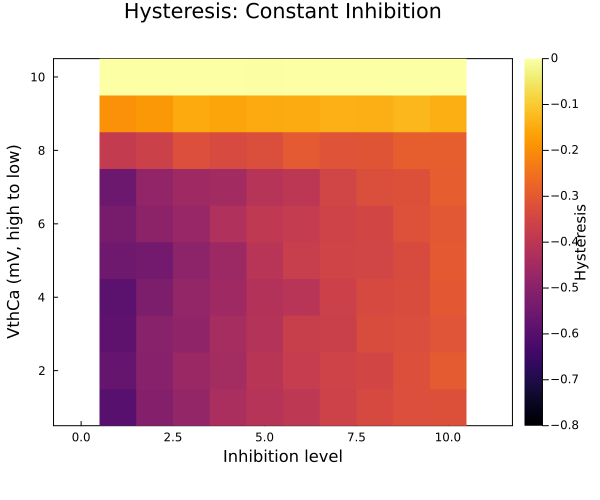

In [21]:
# Prepare data for visualization
hysteresis_plot = copy(hysteresis_constant)
hysteresis_plot[hysteresis_constant .> 99] .= NaN  # Mark invalid as NaN

# Flip rows for intuitive visualization (high VthCa at top)
hysteresis_plot_flipped = reverse(hysteresis_plot, dims=1)

# Create heatmap
Plots.heatmap(hysteresis_plot_flipped,color=:inferno,aspect_ratio=1,
    grid=false,xlabel="Inhibition level",ylabel="VthCa (mV, high to low)",
    title="Hysteresis: Constant Inhibition",frame=:box,clim=(-0.8, 0), 
    colorbar_title="Hysteresis",size=(600, 500))



---

## 5. Save results

### 5.1 Save figures

In [ ]:
# figure_dir = "figures/heatmaps"
# if !isdir(figure_dir)
#     mkpath(figure_dir)
# end
# 
# # Save individual heatmaps
# savefig(joinpath(figure_dir, "heatmap_constant_inhibition.pdf"))
# savefig(joinpath(figure_dir, "heatmap_pushpull_inhibition.pdf"))
# 
# # Save comparison
# savefig(joinpath(figure_dir, "heatmap_comparison.pdf"))
# 
# println("✓ Figures saved to: ", figure_dir)